In [3]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('customer_churn.csv')

In [3]:
df.head()

,CustomerID,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn
0,2.0,30.0,Female,39.0,14.0,5.0,18.0,Standard,Annual,932.0,17.0,1.0
1,3.0,65.0,Female,49.0,1.0,10.0,8.0,Basic,Monthly,557.0,6.0,1.0
2,4.0,55.0,Female,14.0,4.0,6.0,18.0,Basic,Quarterly,185.0,3.0,1.0
3,5.0,58.0,Male,38.0,21.0,7.0,7.0,Standard,Monthly,396.0,29.0,1.0
4,6.0,23.0,Male,32.0,20.0,5.0,8.0,Basic,Monthly,617.0,20.0,1.0


In [4]:
df.shape

(440833, 12)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 440833 entries, 0 to 440832
Data columns (total 12 columns):
 #   Column             Non-Null Count   Dtype  
---  ------             --------------   -----  
 0   CustomerID         440832 non-null  float64
 1   Age                440832 non-null  float64
 2   Gender             440832 non-null  object 
 3   Tenure             440832 non-null  float64
 4   Usage Frequency    440832 non-null  float64
 5   Support Calls      440832 non-null  float64
 6   Payment Delay      440832 non-null  float64
 7   Subscription Type  440832 non-null  object 
 8   Contract Length    440832 non-null  object 
 9   Total Spend        440832 non-null  float64
 10  Last Interaction   440832 non-null  float64
 11  Churn              440832 non-null  float64
dtypes: float64(9), object(3)
memory usage: 40.4+ MB


In [6]:
df['Subscription Type'].value_counts()
df['Contract Length'].value_counts()

Contract Length
Annual       177198
Quarterly    176530
Monthly       87104
Name: count, dtype: int64

In [7]:
df['Churn'].value_counts()

Churn
1.0    249999
0.0    190833
Name: count, dtype: int64

# Data Visualization

<Axes: xlabel='Age', ylabel='Subscription Type'>

C:\ProgramData\anaconda3\Lib\site-packages\IPython\core\events.py:82: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  func(*args, **kwargs)
C:\ProgramData\anaconda3\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


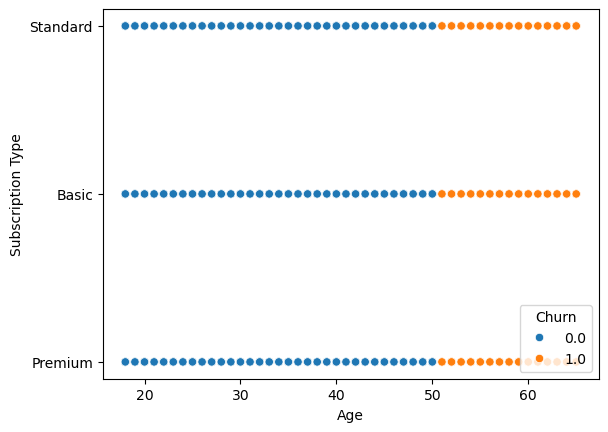

In [28]:
sns.scatterplot(df, x='Age', y='Subscription Type', hue='Churn')

In [9]:
#sns.scatterplot(df, x='Age', y='Support Calls', hue='Subscription Type')

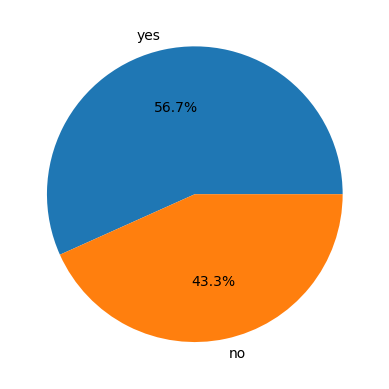

In [29]:
plt.pie(df['Churn'].value_counts(), labels=['yes', 'no'], autopct='%1.1f%%')
plt.show()

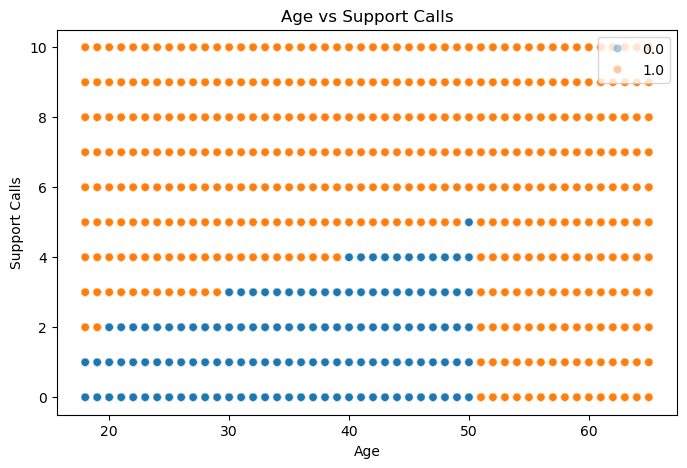

In [34]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='Age',
    y='Support Calls',
    hue='Churn',
    alpha=0.4,
    legend='brief'
)

plt.legend(loc='upper right')
plt.title('Age vs Support Calls')
plt.show()

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from  sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, f1_score, recall_score, confusion_matrix, classification_report
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import GridSearchCV

# Decision Tree Classifier

In [27]:
#Remove missing target values
df = df.dropna(subset=['Churn'])


X = df.drop(['Churn', 'CustomerID'], axis=1)
y = df['Churn'].astype(int)

#Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

#Identify columns
cat_cols = X_train.select_dtypes(include=['object']).columns
num_cols = X_train.select_dtypes(include=['number']).columns


preprocessor = ColumnTransformer([
    ('num', 'passthrough', num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
])

#Complete pipeline
pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', DecisionTreeClassifier(random_state=42))
])

#Hyperparameter grid
param_grid = {
    'classifier__max_depth': [4, 5, 6, 7, 8],
    'classifier__min_samples_split': [10, 20, 30],
    'classifier__min_samples_leaf': [10, 20, 30],
    'classifier__criterion': ['gini', 'entropy']
}

#GridSearchCV
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=3,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)

#Training
grid_search.fit(X_train, y_train)


best_model = grid_search.best_estimator_

print("Best Parameters:", grid_search.best_params_)
print("Best CV F1:", grid_search.best_score_)


y_pred = best_model.predict(X_test)

#Evaluation
print("\nAccuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))

print("\nClassification Report:\n", classification_report(y_test, y_pred))

Fitting 3 folds for each of 90 candidates, totalling 270 fits
Best Parameters: {'classifier__criterion': 'gini', 'classifier__max_depth': 8, 'classifier__min_samples_leaf': 10, 'classifier__min_samples_split': 10}
Best CV F1: 0.9944667085227591

Accuracy: 0.993625708884688
Precision: 0.9999460662037349
Recall: 0.9888133333333333
F1 Score: 0.9943485402071531

Confusion Matrix:
 [[57246     4]
 [  839 74161]]

Classification Report:
               precision    recall  f1-score   support

           0       0.99      1.00      0.99     57250
           1       1.00      0.99      0.99     75000

    accuracy                           0.99    132250
   macro avg       0.99      0.99      0.99    132250
weighted avg       0.99      0.99      0.99    132250



In [17]:
print(df.corr(numeric_only=True)['Churn'].sort_values(ascending=False))

Churn               1.000000
Support Calls       0.574267
Payment Delay       0.312129
Age                 0.218394
Last Interaction    0.149616
Usage Frequency    -0.046101
Tenure             -0.051919
Total Spend        -0.429355
CustomerID         -0.839365
Name: Churn, dtype: float64


<Axes: >

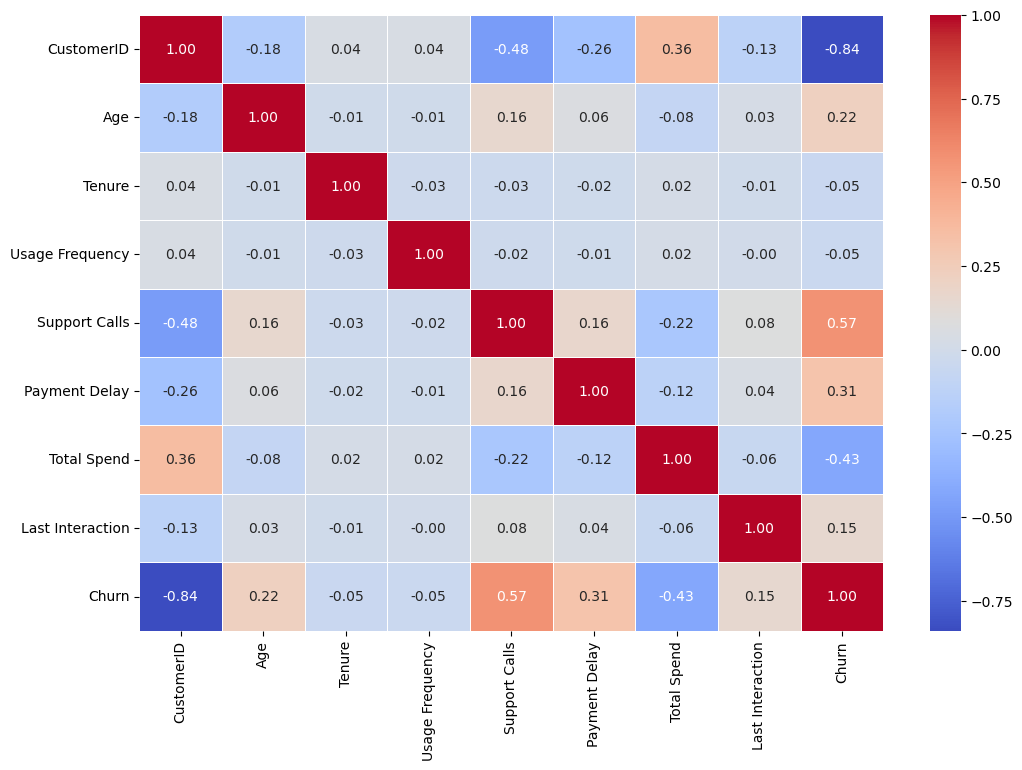

In [31]:
corr = df.corr(numeric_only=True)

plt.figure(figsize=(12, 8))

sns.heatmap(
    corr,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

# KNN Classifier

In [36]:
from sklearn.neighbors import KNeighborsClassifier

#Remove missing target values
df = df.dropna(subset=['Churn'])


X = df.drop(['Churn', 'CustomerID'], axis=1)
y = df['Churn'].astype(int)

#Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

#Identify columns
cat_cols = X_train.select_dtypes(include=['object']).columns
num_cols = X_train.select_dtypes(include=['number']).columns


preprocessor = ColumnTransformer([
    ('num', 'passthrough', num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
])

#Complete pipeline
pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', KNeighborsClassifier())
])

#Hyperparameter grid
param_grid = {
    'classifier__n_neighbors': [3, 5, 7, 9, 11]
}

#GridSearchCV
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=3,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)

#Training
grid_search.fit(X_train, y_train)


best_model = grid_search.best_estimator_

print("Best Parameters:", grid_search.best_params_)
print("Best CV F1:", grid_search.best_score_)


y_pred = best_model.predict(X_test)

#Evaluation
print("\nAccuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))

print("\nClassification Report:\n", classification_report(y_test, y_pred))

Fitting 3 folds for each of 5 candidates, totalling 15 fits
Best Parameters: {'classifier__n_neighbors': 5}
Best CV F1: 0.8897648328405269

Accuracy: 0.8907145557655954
Precision: 0.9754228371311463
Recall: 0.82816
F1 Score: 0.8957794010542484

Confusion Matrix:
 [[55685  1565]
 [12888 62112]]

Classification Report:
               precision    recall  f1-score   support

           0       0.81      0.97      0.89     57250
           1       0.98      0.83      0.90     75000

    accuracy                           0.89    132250
   macro avg       0.89      0.90      0.89    132250
weighted avg       0.90      0.89      0.89    132250



# Logistic Regression

In [37]:
from sklearn.linear_model import LogisticRegression

#Remove missing target values
df = df.dropna(subset=['Churn'])


X = df.drop(['Churn', 'CustomerID'], axis=1)
y = df['Churn'].astype(int)

#Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42,
    stratify=y
)

#Identify columns
cat_cols = X_train.select_dtypes(include=['object']).columns
num_cols = X_train.select_dtypes(include=['number']).columns


preprocessor = ColumnTransformer([
    ('num', 'passthrough', num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore'), cat_cols)
])

#Complete pipeline
pipeline = Pipeline([
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression())
])

#Hyperparameter grid
param_grid = {
    'classifier__C': [0.01, 0.1, 1, 10, 100],
    'classifier__penalty': ['l1', 'l2'],
    'classifier__solver': ['liblinear'],
    'classifier__class_weight': [None, 'balanced'],
    'classifier__max_iter': [500, 1000]
}

#GridSearchCV
grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=3,
    scoring='f1',
    n_jobs=-1,
    verbose=1
)

#Training
grid_search.fit(X_train, y_train)


best_model = grid_search.best_estimator_

print("Best Parameters:", grid_search.best_params_)
print("Best CV F1:", grid_search.best_score_)


y_pred = best_model.predict(X_test)

#Evaluation
print("\nAccuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(y_test, y_pred))
print("Recall:", recall_score(y_test, y_pred))
print("F1 Score:", f1_score(y_test, y_pred))

print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))

print("\nClassification Report:\n", classification_report(y_test, y_pred))

Fitting 3 folds for each of 40 candidates, totalling 120 fits
Best Parameters: {'classifier__C': 0.01, 'classifier__class_weight': None, 'classifier__max_iter': 500, 'classifier__penalty': 'l1', 'classifier__solver': 'liblinear'}
Best CV F1: 0.906244107150162

Accuracy: 0.8943213610586012
Precision: 0.9241194295404631
Recall: 0.88644
F1 Score: 0.9048876427433954

Confusion Matrix:
 [[51791  5459]
 [ 8517 66483]]

Classification Report:
               precision    recall  f1-score   support

           0       0.86      0.90      0.88     57250
           1       0.92      0.89      0.90     75000

    accuracy                           0.89    132250
   macro avg       0.89      0.90      0.89    132250
weighted avg       0.90      0.89      0.89    132250

